# Input perturbations: context splicing & temporal receptive field

This notebook probes **what behavioural context the encoder uses** to predict
spikes, using input perturbations and a context-length training sweep on a
trained encoder (`encoder-opt`, the Optuna-searched `Bat_Transformer`;
trajectory branch only, 3-D position input).

**Part 1 — Context-swap / splicing.** At every bin (the "firing moment") we hold
a short window of the *focal* flight fixed and replace the rest of the sequence
with *donor* context from another flight. We sweep the kept-window size
(1, 3, 5, 7, 9, 11 bins, or all = no swap) and compare four donor conditions:
(1) no swap, (2) same-cluster donor, (3) same-route different-cluster donor,
(4) different-route donor. Routes are `perch→reward`, `reward→perch`,
`reward→reward`.

**Part 2 — Temporal receptive-field ablation.** We limit how far attention can
reach by masking each bin to a ±(W-1)/2 window (1, 3, 5, 7, 9, 11, or full) using
the model's **own padding mask** — the regime it was trained with, so no BigBird
or out-of-distribution attention pattern — and find the minimum window that
recovers full-attention encoding.

**Part 3 — Train-time context length.** Rather than ablating the full model, we
**train new encoders that differ only in context length** (`window_size` ∈
1, 3, 5, 7, 9, 11, full), tiling each flight into batch-stacked segments so the
whole flight is still seen. Same architecture / training recipe as encode-opt;
we compare encoding vs context length and overlay the Part 2 ablation.

Parts 1–2 evaluate **every bin of every flight** (read off the diagonal of a
per-center batch), then pool predictions across flights before scoring per-neuron
`corr` / Poisson `FDE`.

The model is loaded behind a single `load_encoder()` factory so we can swap in
the joint encoder once it is trained (see the `MODEL_CHOICE` switch).


In [ ]:
%load_ext autoreload
%autoreload 2

import os
import sys
import json as _json
from collections import defaultdict

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import torch

sys.path.append(os.path.expanduser('~/Documents/code/digitalbat'))
sys.path.append(os.path.dirname(os.path.abspath('.')) + '/notebooks')
sys.path.append('.')  # notebooks/ is the cwd; pull in notebook_helpers

from digitalbat.datasets.data import bat_data_loader
from digitalbat.datasets.defaults import DEFAULT_SESSION_NAMES, make_data_config
from digitalbat.models.former import Bat_Transformer
from digitalbat.models.former_defaults import (
    DEFAULT_LR, DEFAULT_WEIGHT_DECAY, make_model_config, make_model_name,
    make_trainer_config,
)
from digitalbat.training.trainer import bat_former_trainer
from digitalbat.utility.utils import (
    corr, poisson_fde_population, set_random_state,
    bat_palette, parse_bat, wilcoxon_safe,
    add_significance_bracket, stars_for_p,
)
from notebook_helpers import compute_target_proximity, DIST_THRESH

sns.set_context('talk')
sns.set_style('ticks')


In [25]:
seed = 1
set_random_state(seed)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
rng = np.random.default_rng(seed)

# --- which trained model to probe -------------------------------------------
# 'encoder-opt'  -> Optuna-searched Bat_Transformer (trajectory branch, position).
# 'joint'        -> placeholder for the joint masked encode/decode model; wire up
#                   load_encoder() below once that checkpoint is trained.
MODEL_CHOICE = 'encoder-opt'

# Checkpoint tag that defines the train/valid/test split (see model_comparison).
DATA_TAG = '_acc50_preln_17_sess'

# --- perturbation sweep settings --------------------------------------------
# Window = number of contiguous focal bins kept around the firing moment.
WINDOWS = [1, 3, 5, 7, 9, 11]           # 'all' (= no swap) handled separately
# Routes we splice between (start_loc -> end_loc).
ROUTES = ['perch->reward', 'reward->perch', 'reward->reward']
# Donors drawn per focal flight per condition (averages over context identity).
K_DONORS = 10
# Cap focal flights per session (None = use all); lower for a quick smoke test.
MAX_FOCAL_PER_SESSION = None
# Minimum flight length (valid bins) to be eligible as focal/donor.
MIN_FLIGHT_BINS = 5


In [26]:
data_config = make_data_config(session_names=DEFAULT_SESSION_NAMES)
dataloaders, behavior_dim, unit_num_dict, meta_info_dict = bat_data_loader(**data_config)
print(f'behavior_dim={behavior_dim}, sessions={len(unit_num_dict)}, '
      f'total neurons={sum(unit_num_dict.values())}')


  Acceleration filter: removed 1/136 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 9/154 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/131 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/79 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/78 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/77 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/82 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/98 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/112 flights (peak |acc| > 50 m/s²)
behavior_dim=3, sessions=17, total neurons=3080


## Load the trained encoder

`load_encoder()` returns an eval-mode model exposing
`model(session_name, X, mask, ...)`. For `encoder-opt` we rebuild the
Optuna-searched architecture and load the checkpoint exactly as
`model_comparison.ipynb` does. The `joint` branch is a stub to fill in once the
joint encoder is trained.


In [27]:
def load_encoder(model_choice=MODEL_CHOICE):
    if model_choice == 'encoder-opt':
        arch_path = f'./out/bat_former/former_best_params{DATA_TAG}_seed_{seed}.json'
        if os.path.exists(arch_path):
            bp = _json.load(open(arch_path))
            arch = {k: bp[k] for k in ('latent_dim', 'ff_dim', 'num_layers',
                                       'dropout_prob') if k in bp}
            print(f'encoder arch overrides: {arch}')
        else:
            arch = {}
            print(f'WARNING: {arch_path} missing; using make_model_config defaults')
        cfg = make_model_config(behavior_dim, unit_num_dict, meta_info_dict, **arch)
        model = Bat_Transformer(**cfg)
        ckpt = make_model_name(seed, DEFAULT_LR, DEFAULT_WEIGHT_DECAY,
                               out_dir='./out/bat_former', suffix=DATA_TAG)
        miss, unexp = model.load_state_dict(torch.load(ckpt, map_location=device),
                                            strict=False)
        print(f'loaded {ckpt}\n  missing={len(miss)} unexpected={len(unexp)}')
        return model.to(device).eval()

    if model_choice == 'joint':
        raise NotImplementedError(
            'Wire up the joint encoder checkpoint here (JointEncoderAdapter '
            'presenting the Bat_Transformer(session, X, mask, ...) interface). '
            'See joint-encode-decode.ipynb / internals.ipynb.')

    raise ValueError(model_choice)


model = load_encoder()


encoder arch overrides: {'latent_dim': 64, 'ff_dim': 128, 'num_layers': 2, 'dropout_prob': 0.39972627597342025}
loaded ./out/bat_former/bat_former_seed_1_lr_1.00e-02_wd_1.00e-02_acc50_preln_17_sess.pth
  missing=0 unexpected=0


## Build a per-flight table with route labels

`window_size=None` gives one (padded) row per flight, so each test-set row is a
full flight. We de-normalize position back to metres (`x = z·σ + μ`) to label
the start/end as perch vs reward via `compute_target_proximity`, then keep only
flights whose route is one of `ROUTES`.

Each table entry stores the **normalized** behaviour (model input space), the
true spikes, the flight cluster id, and the route label.


In [28]:
def denorm(beh_norm, session_name):
    """(T,3) normalized -> (T,3) metres using the session's behaviour stats."""
    mu = np.asarray(meta_info_dict['behavior_mean'][session_name]).reshape(-1)[:3]
    sd = np.asarray(meta_info_dict['behavior_std'][session_name]).reshape(-1)[:3]
    return beh_norm * sd + mu


def loc_kind(pos_m, session_name):
    """Classify a single 3-D position (metres) as 'reward'/'perch'/'other'."""
    prox = compute_target_proximity(pos_m[None], session_name=session_name)
    if prox['at_rew'][0]:
        return 'reward'
    if prox['at_perch'][0]:
        return 'perch'
    return 'other'


def build_flight_table(dataloaders, split='test'):
    rows = []
    for session_name, loader in dataloaders[split].items():
        bat = parse_bat(session_name)
        for batch in loader:
            beh = batch.behavior.numpy()                 # (N, T, 3) normalized
            spk = batch.spike.numpy()                    # (N, T, n_neurons)
            msk = batch.mask.numpy().astype(bool)        # (N, T)
            fpi = batch.flight_path_index.numpy()
            fti = batch.flight_type_index.numpy()
            for i in range(beh.shape[0]):
                v = msk[i]
                if v.sum() < MIN_FLIGHT_BINS:
                    continue
                b = beh[i][v]                            # (T_i, 3) normalized
                s = spk[i][v]                            # (T_i, n_neurons)
                pos_m = denorm(b, session_name)
                route = f"{loc_kind(pos_m[0], session_name)}->" \
                        f"{loc_kind(pos_m[-1], session_name)}"
                rows.append(dict(
                    session=session_name, bat=bat,
                    path=int(fpi[i]), cluster=int(fti[i]), route=route,
                    n_bins=int(v.sum()), beh=b, spk=s,
                ))
    return pd.DataFrame(rows)


flights = build_flight_table(dataloaders, 'test')
print(f'{len(flights)} test flights total')
print(flights['route'].value_counts())

# Keep only the routes we splice between, and only sessions that have >=2 of them
# (need a focal + at least one donor).
flights = flights[flights['route'].isin(ROUTES)].reset_index(drop=True)
print(f'\n{len(flights)} flights on target routes across '
      f"{flights['session'].nunique()} sessions")
display(flights.groupby(['route']).agg(n_flights=('path', 'size'),
                                       n_clusters=('cluster', 'nunique')))


281 test flights total
route
reward->perch     92
perch->reward     92
reward->reward    41
perch->perch      25
other->perch      10
reward->other      8
other->reward      6
perch->other       4
other->other       3
Name: count, dtype: int64

225 flights on target routes across 17 sessions


,n_flights,n_clusters
route,,
perch->reward,92,20
reward->perch,92,19
reward->reward,41,15


## Part 1 — Context-swap / splicing

For a focal flight of length `T` and a donor flight, we resample the donor to
`T` bins (linear interpolation along its path, in normalized space). For window
size `W` (half-width `r=(W-1)/2`) we build `T` spliced sequences — sequence `c`
keeps focal bins `[c-r, c+r]` and takes donor bins everywhere else — run them in
one forward pass, and read the prediction at the **diagonal** (bin `c` of
sequence `c`). That gives the model's spike prediction at every firing moment
when only a `W`-bin focal window survives.

`W = all` keeps the whole focal flight regardless of donor, so every swap
condition collapses to the unperturbed **no-swap** prediction there.

Per `(session, condition, W)` we pool the spliced predictions across all focal
flights and their `K_DONORS` donors, then score per-neuron `corr` / Poisson
`FDE` against the true spikes — the same vstack-then-score pattern as
`evaluate_model`.


In [29]:
def resample_to(beh, T):
    """Resample a (Td,3) sequence to (T,3) by linear interp along the path."""
    Td = beh.shape[0]
    if Td == T:
        return beh.copy()
    src = np.linspace(0.0, 1.0, Td)
    dst = np.linspace(0.0, 1.0, T)
    return np.stack([np.interp(dst, src, beh[:, d]) for d in range(beh.shape[1])], axis=1)


@torch.no_grad()
def spliced_diag_pred(model, session_name, focal_beh, donor_beh, W):
    """Predictions at each firing moment with a W-bin focal window spliced into
    donor context. Returns (T, n_neurons)."""
    T = focal_beh.shape[0]
    r = (W - 1) // 2
    donor_rs = resample_to(donor_beh, T)
    X = np.broadcast_to(donor_rs, (T, T, 3)).copy()      # (center, time, 3)
    for c in range(T):
        lo, hi = max(0, c - r), min(T, c + r + 1)
        X[c, lo:hi] = focal_beh[lo:hi]
    Xt = torch.from_numpy(X).float().to(device)
    mask = torch.ones(T, T, device=device)
    out = model(session_name, Xt, mask)                  # (T, T, n_neurons)
    diag = out[torch.arange(T), torch.arange(T)]         # (T, n_neurons)
    return diag.cpu().numpy()


@torch.no_grad()
def unperturbed_pred(model, session_name, focal_beh):
    """No-swap prediction for the full focal flight. (T, n_neurons)."""
    T = focal_beh.shape[0]
    Xt = torch.from_numpy(focal_beh[None]).float().to(device)
    mask = torch.ones(1, T, device=device)
    return model(session_name, Xt, mask)[0].cpu().numpy()


def pick_donors(sess_flights, focal, condition, k, rng):
    """Return up to k donor rows for the given condition."""
    others = sess_flights[sess_flights['path'] != focal['path']]
    if condition == 'same cluster':
        pool = others[others['cluster'] == focal['cluster']]
    elif condition == 'same route':
        pool = others[(others['route'] == focal['route']) &
                      (others['cluster'] != focal['cluster'])]
    elif condition == 'diff route':
        pool = others[others['route'] != focal['route']]
    else:
        raise ValueError(condition)
    if len(pool) == 0:
        return []
    idx = rng.choice(pool.index.values, size=min(k, len(pool)), replace=False)
    return [pool.loc[i] for i in idx]


In [30]:
SWAP_CONDITIONS = ['same cluster', 'same route', 'diff route']

# acc[(session, condition, W)] = (list_of_pred_chunks, list_of_true_chunks)
acc = defaultdict(lambda: ([], []))
# no-swap reference accumulates once per session (constant across W)
acc_noswap = defaultdict(lambda: ([], []))

for session_name, sess_flights in flights.groupby('session'):
    sess_flights = sess_flights.copy()
    focal_rows = sess_flights
    if MAX_FOCAL_PER_SESSION is not None and len(focal_rows) > MAX_FOCAL_PER_SESSION:
        focal_rows = focal_rows.sample(MAX_FOCAL_PER_SESSION, random_state=seed)
    for _, focal in focal_rows.iterrows():
        # no-swap reference (= W all)
        pred0 = unperturbed_pred(model, session_name, focal['beh'])
        acc_noswap[session_name][0].append(pred0)
        acc_noswap[session_name][1].append(focal['spk'])
        for condition in SWAP_CONDITIONS:
            donors = pick_donors(sess_flights, focal, condition, K_DONORS, rng)
            for donor in donors:
                for W in WINDOWS:
                    pred = spliced_diag_pred(model, session_name,
                                             focal['beh'], donor['beh'], W)
                    key = (session_name, condition, W)
                    acc[key][0].append(pred)
                    acc[key][1].append(focal['spk'])
    print(f'{session_name}: {len(focal_rows)} focal flights done')

print('swap sweep complete')


Dataset_1_32622_231007: 14 focal flights done
Dataset_1_32622_231009: 13 focal flights done
Dataset_1_32622_231010: 15 focal flights done
Dataset_2_14445_231208: 10 focal flights done
Dataset_2_14445_231209: 11 focal flights done
Dataset_2_14611_231208: 3 focal flights done
Dataset_2_14611_231209: 11 focal flights done
Dataset_3_00000_240402: 9 focal flights done
Dataset_3_00000_240403: 15 focal flights done
Dataset_3_00000_240404: 17 focal flights done
Dataset_3_00000_240405: 19 focal flights done
Dataset_3_14543_240420: 18 focal flights done
Dataset_3_14543_240421: 16 focal flights done
Dataset_3_29959_240402: 13 focal flights done
Dataset_3_29959_240403: 13 focal flights done
Dataset_3_29959_240404: 13 focal flights done
Dataset_3_29959_240405: 15 focal flights done
swap sweep complete


In [31]:
def score_chunks(preds, trues):
    """Per-neuron corr and FDE over pooled (sum T, n_neurons) arrays."""
    yp = np.vstack(preds)
    yt = np.vstack(trues)
    return corr(yt, yp, axis=0), poisson_fde_population(yt, yp)


rows = []
for (session_name, condition, W), (preds, trues) in acc.items():
    if not preds:
        continue
    c, f = score_chunks(preds, trues)
    bat = parse_bat(session_name)
    for n in range(len(c)):
        rows.append(dict(session=session_name, bat=bat, condition=condition,
                         window=W, neuron=n, corr=c[n], fde=f[n]))

# no-swap reference: replicate across every window for plotting
for session_name, (preds, trues) in acc_noswap.items():
    if not preds:
        continue
    c, f = score_chunks(preds, trues)
    bat = parse_bat(session_name)
    for W in WINDOWS + ['all']:
        for n in range(len(c)):
            rows.append(dict(session=session_name, bat=bat, condition='no swap',
                             window=W, neuron=n, corr=c[n], fde=f[n]))

swap_df = pd.DataFrame(rows)
# numeric x position; 'all' sits just past the largest finite window
ALL_X = max(WINDOWS) + 2
swap_df['window_x'] = swap_df['window'].replace({'all': ALL_X}).astype(float)
print(swap_df.shape)
swap_df.head()


(74468, 8)


/tmp/ipykernel_1921349/1277502894.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  swap_df['window_x'] = swap_df['window'].replace({'all': ALL_X}).astype(float)


,session,bat,condition,window,neuron,corr,fde,window_x
0,Dataset_1_32622_231007,32622,same cluster,1,0,0.260173,0.063975,1.0
1,Dataset_1_32622_231007,32622,same cluster,1,1,0.464257,0.315657,1.0
2,Dataset_1_32622_231007,32622,same cluster,1,2,0.466980,0.237618,1.0
3,Dataset_1_32622_231007,32622,same cluster,1,3,0.328090,0.073265,1.0
4,Dataset_1_32622_231007,32622,same cluster,1,4,0.234491,0.045321,1.0


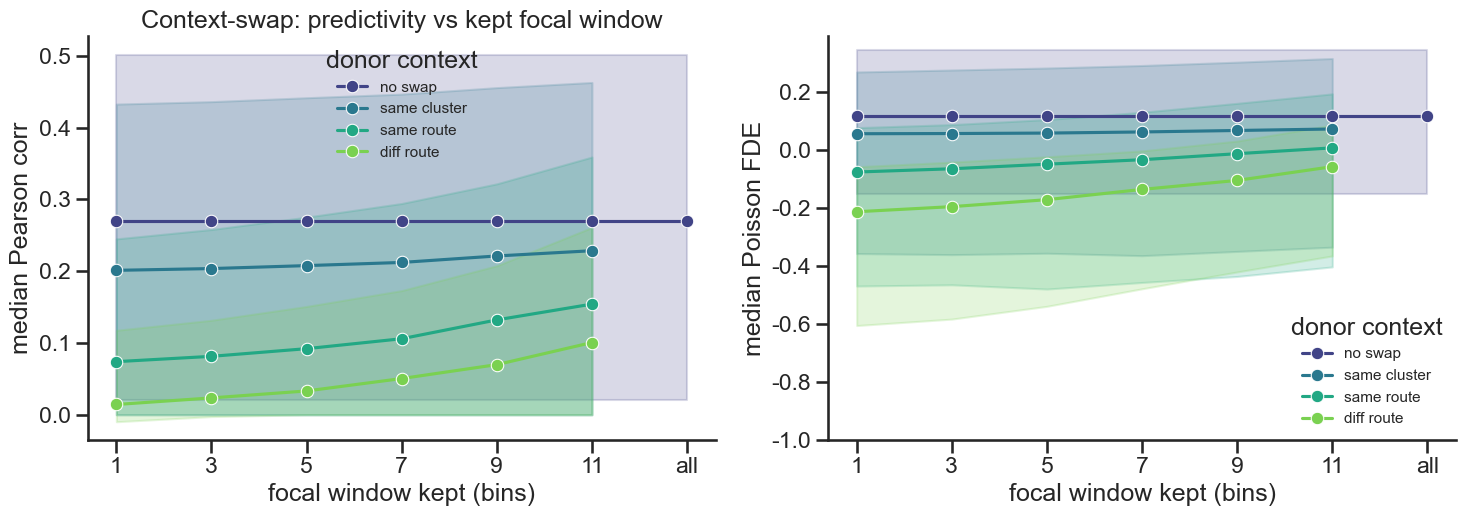

In [32]:
COND_ORDER = ['no swap', 'same cluster', 'same route', 'diff route']
cond_pal = dict(zip(COND_ORDER, sns.color_palette('viridis', len(COND_ORDER))))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, (metric, label) in zip(axes, [('corr', 'Pearson corr'),
                                       ('fde', 'Poisson FDE')]):
    sns.lineplot(data=swap_df, x='window_x', y=metric, hue='condition',
                 hue_order=COND_ORDER, palette=cond_pal, estimator='median',
                 errorbar=('pi', 50), marker='o', ax=ax)
    ax.set_xticks(WINDOWS + [ALL_X])
    ax.set_xticklabels([str(w) for w in WINDOWS] + ['all'])
    ax.set_xlabel('focal window kept (bins)')
    ax.set_ylabel(f'median {label}')
    if metric == 'fde':                       # FDE unbounded below; clip the AXIS only
        ax.set_ylim(-1, ax.get_ylim()[1])
    ax.legend(title='donor context', fontsize=11)
axes[0].set_title('Context-swap: predictivity vs kept focal window')
sns.despine(fig)
plt.tight_layout()
plt.show()


### Smallest-window comparison (session-level, by bat)

At `W = 1` only the firing-moment position survives, so the donor context drives
everything. We compare conditions across sessions (session-level medians,
nonparametric Wilcoxon, points coloured by bat) — the convention used elsewhere
in this project.


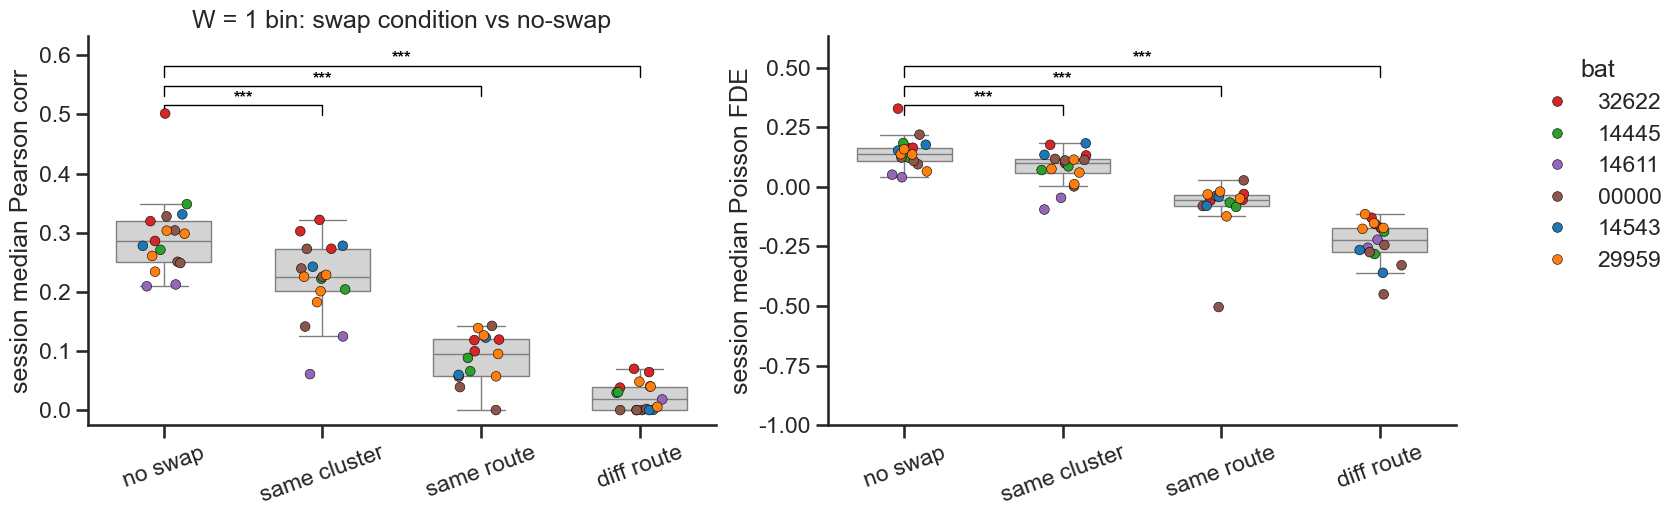

In [33]:
W_PROBE = WINDOWS[0]
bat_pal = bat_palette()

# session-level median per condition at the probe window
sess_med = (swap_df[swap_df['window'] == W_PROBE]
            .groupby(['session', 'bat', 'condition'])[['corr', 'fde']]
            .median().reset_index())

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, (metric, label) in zip(axes, [('corr', 'Pearson corr'),
                                       ('fde', 'Poisson FDE')]):
    sns.boxplot(data=sess_med, x='condition', y=metric, order=COND_ORDER,
                color='lightgray', width=0.6, showfliers=False, ax=ax)
    sns.stripplot(data=sess_med, x='condition', y=metric, order=COND_ORDER,
                  hue='bat', palette=bat_pal, size=7, jitter=0.15,
                  edgecolor='k', linewidth=0.4, ax=ax)
    if metric == 'fde':
        ax.set_ylim(-1, ax.get_ylim()[1])
    # paired Wilcoxon of each swap condition vs no-swap, across sessions
    pivot = sess_med.pivot_table(index='session', columns='condition',
                                 values=metric)
    base = pivot['no swap']
    for j, cond in enumerate(COND_ORDER[1:], start=1):
        if cond not in pivot:
            continue
        _, p = wilcoxon_safe(pivot[cond] - base)
        add_significance_bracket(ax, 0, j, p)
    ax.set_xlabel('')
    ax.set_ylabel(f'session median {label}')
    ax.tick_params(axis='x', rotation=20)
axes[0].set_title(f'W = {W_PROBE} bin: swap condition vs no-swap')
# one shared bat legend; drop the per-axis stripplot legends
handles, labels = axes[1].get_legend_handles_labels()
for ax in axes:
    if ax.get_legend() is not None:
        ax.get_legend().remove()
fig.legend(handles, labels, title='bat', bbox_to_anchor=(1.02, 0.9),
           loc='upper left')
sns.despine(fig)
plt.tight_layout()
plt.show()


## Part 2 — Temporal receptive-field ablation

We limit how far attention can reach **using the model's own padding mask** — the
exact regime it was trained with — rather than BigBird (which imposes a sliding
pattern the baseline never saw). For window `W` (half-width `r=(W-1)/2`) we keep
the full focal flight but mask bin `c` so it attends only to bins `[c-r, c+r]`,
then read the diagonal (bin `c` of sequence `c`). Because out-of-window bins are
masked at **every** layer, this gives an *exact* ±r-bin receptive field (no
cross-layer compounding). `W = all` is ordinary full attention and reproduces the
baseline encoding. We sweep `W` and find the minimum that recovers it.

This reuses Part 1's diagonal machinery: it is the splice with the donor replaced
by "nothing" (out-of-window bins dropped via the mask instead of overwritten).


In [34]:
# Temporal receptive field via the padding mask (no BigBird): keep the full focal
# flight but let bin c attend only to bins [c-r, c+r]. Out-of-window bins are
# masked exactly like padding -- the regime the encoder was trained with, so no
# out-of-distribution attention pattern is introduced. Read the diagonal.
@torch.no_grad()
def windowed_diag_pred(model, session_name, focal_beh, W):
    """Predict each bin with attention restricted to a +/-(W-1)/2 window via the
    padding mask. W='all' -> full attention. Returns (T, n_neurons)."""
    if W == 'all':
        return unperturbed_pred(model, session_name, focal_beh)
    T = focal_beh.shape[0]
    r = (W - 1) // 2
    X = np.broadcast_to(focal_beh, (T, T, 3)).copy()     # (center, time, 3)
    m = np.zeros((T, T), dtype=np.float32)
    for c in range(T):
        lo, hi = max(0, c - r), min(T, c + r + 1)
        m[c, lo:hi] = 1.0                                # bin c attends only here
    out = model(session_name, torch.from_numpy(X).float().to(device),
                torch.from_numpy(m).to(device))          # (T, T, n_neurons)
    return out[torch.arange(T), torch.arange(T)].cpu().numpy()


# All test flights (not just the routed subset) for a general RF estimate.
flights_all = build_flight_table(dataloaders, 'test')
print(f'{len(flights_all)} test flights for the RF ablation')

rf_rows = []
for W in WINDOWS + ['all']:
    acc_rf = defaultdict(lambda: ([], []))
    for _, fl in flights_all.iterrows():
        pred = windowed_diag_pred(model, fl['session'], fl['beh'], W)
        acc_rf[fl['session']][0].append(pred)
        acc_rf[fl['session']][1].append(fl['spk'])
    for session_name, (preds, trues) in acc_rf.items():
        c, f = score_chunks(preds, trues)
        bat = parse_bat(session_name)
        for n in range(len(c)):
            rf_rows.append(dict(session=session_name, bat=bat, window=W,
                                neuron=n, corr=c[n], fde=f[n]))
    cc = np.array([r['corr'] for r in rf_rows if r['window'] == W])
    print(f'W={W!s:>3}: median corr={np.nanmedian(cc):+.4f}')

rf_df = pd.DataFrame(rf_rows)
rf_df['window_x'] = rf_df['window'].replace({'all': ALL_X}).astype(float)


281 test flights for the RF ablation
W=  1: median corr=+0.0232
W=  3: median corr=+0.0316
W=  5: median corr=+0.0515
W=  7: median corr=+0.0834
W=  9: median corr=+0.1191
W= 11: median corr=+0.1471
W=all: median corr=+0.2653


/tmp/ipykernel_1921349/3220069212.py:44: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  rf_df['window_x'] = rf_df['window'].replace({'all': ALL_X}).astype(float)


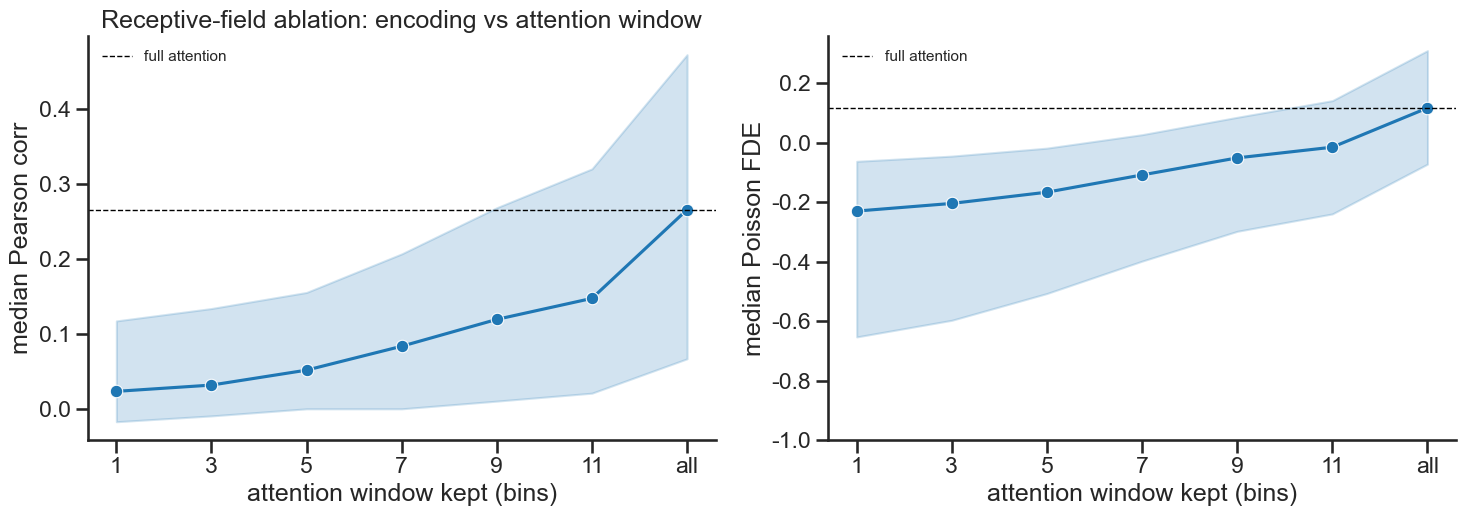

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, (metric, label) in zip(axes, [('corr', 'Pearson corr'),
                                       ('fde', 'Poisson FDE')]):
    sns.lineplot(data=rf_df, x='window_x', y=metric, estimator='median',
                 errorbar=('pi', 50), marker='o', color='C0', ax=ax)
    full = rf_df[rf_df['window'] == 'all'][metric].median()
    ax.axhline(full, ls='--', color='k', lw=1, label='full attention')
    # minimum window reaching 95% of full-attention median
    med = (rf_df[rf_df['window'] != 'all'].groupby('window_x')[metric]
           .median())
    thresh = 0.95 * full if full > 0 else full
    recovered = med[med >= thresh]
    if len(recovered):
        wmin = recovered.index.min()
        ax.axvline(wmin, ls=':', color='crimson', lw=1.5)
        ax.text(wmin, ax.get_ylim()[0], f'  min W={int(wmin)}',
                color='crimson', va='bottom', fontsize=12)
    ax.set_xticks(WINDOWS + [ALL_X])
    ax.set_xticklabels([str(w) for w in WINDOWS] + ['all'])
    ax.set_xlabel('attention window kept (bins)')
    ax.set_ylabel(f'median {label}')
    if metric == 'fde':
        ax.set_ylim(-1, ax.get_ylim()[1])
    ax.legend(fontsize=11)
axes[0].set_title('Receptive-field ablation: encoding vs attention window')
sns.despine(fig)
plt.tight_layout()
plt.show()


## Part 3 — Train-time context length

Parts 1–2 ablate a model trained on full flights. Here we instead **train new
encoders that differ only in their context length**. Each flight is split into
non-overlapping length-`W` segments (`window_size=W`, `stride=W`; the tail is
NaN-padded + masked) **stacked along the batch dimension**, so the whole flight
is still seen during training/eval but no prediction can attend beyond `W` bins.
`W = full` is the existing `encoder-opt` (whole flight in one sequence), reused
directly rather than retrained.

Every model uses encode-opt's architecture and training recipe — the same
`make_model_config` overrides and `make_trainer_config` (Poisson NLL, FDE-median
early stopping, lr = wd = 0.01) — so **only the context length changes**. We then
compare test-set corr / FDE versus context length, and overlay Part 2's
inference-time attention ablation of the full model for contrast (trained-for-short
vs full-model-restricted-at-inference).

> **Cost:** trains up to 6 models at encode-opt's 1000-epoch / patience-100
> settings; small `W` has many segments and runs slower. Checkpoints are cached
> under `out/bat_former_ctxlen/` (re-runs load instead of retrain). Lower
> `CTX_N_EPOCHS` / `CTX_PATIENCE` for a quick pass.


In [ ]:
# Context lengths to train (full = the already-loaded encoder-opt).
CTX_WINDOWS = WINDOWS                       # [1, 3, 5, 7, 9, 11]
CTX_CKPT_DIR = './out/bat_former_ctxlen'
CTX_N_EPOCHS = 1000                         # encode-opt defaults (make_trainer_config)
CTX_PATIENCE = 100
os.makedirs(CTX_CKPT_DIR, exist_ok=True)

# encode-opt architecture overrides (same set load_encoder() uses).
_cbp = _json.load(open(f'./out/bat_former/former_best_params{DATA_TAG}_seed_{seed}.json'))
CTX_ARCH = {k: _cbp[k] for k in ('latent_dim', 'ff_dim', 'num_layers',
                                 'dropout_prob') if k in _cbp}

# Tiled dataloaders: window_size=W, stride=W splits each flight into
# non-overlapping length-W segments (tail NaN-padded + masked) stacked along the
# batch dim, so the whole flight is still seen while no prediction attends beyond
# W bins. The train/test flight SPLIT is fixed by clustering (independent of
# window_size), so only the context length changes across W. 'full' reuses the
# window_size=None loaders already built above (one segment = the whole flight).
base_dc = make_data_config(session_names=DEFAULT_SESSION_NAMES)
ctx_dataloaders = {'full': dataloaders}
for W in CTX_WINDOWS:
    dlW, _, _, _ = bat_data_loader(**{**base_dc, 'window_size': W,
                                      'stride_train': W, 'stride_test': W})
    ctx_dataloaders[W] = dlW
    n_tr = sum(len(d.dataset) for d in dlW['train'].values())
    n_te = sum(len(d.dataset) for d in dlW['test'].values())
    print(f'context {W:>2}: {n_tr} train / {n_te} test segments')


In [ ]:
# Train (or load) one encoder per context length. 'full' = encoder-opt (already
# loaded as `model`), so it is not retrained. Each model uses encode-opt's exact
# architecture + training recipe; only the input context length differs.
def make_ctx_model():
    return Bat_Transformer(**make_model_config(
        behavior_dim, unit_num_dict, meta_info_dict, **CTX_ARCH)).to(device)


ctx_models = {'full': model}
for W in CTX_WINDOWS:
    path = make_model_name(seed, DEFAULT_LR, DEFAULT_WEIGHT_DECAY,
                           out_dir=CTX_CKPT_DIR, suffix=f'{DATA_TAG}_ctx{W}')
    set_random_state(seed)
    m = make_ctx_model()
    if os.path.exists(path):
        m.load_state_dict(torch.load(path, map_location=device), strict=False)
        print(f'context {W:>2}: loaded {os.path.basename(path)}')
    else:
        print(f'context {W:>2}: training (this can take a while) ...')
        tc = make_trainer_config(model=m, dataloaders=ctx_dataloaders[W],
                                 device=device, model_name=path,
                                 lr=DEFAULT_LR, weight_decay=DEFAULT_WEIGHT_DECAY,
                                 n_epochs=CTX_N_EPOCHS,
                                 early_stopping_patience=CTX_PATIENCE)
        bv, best_w, _ = bat_former_trainer(**tc)
        torch.save(best_w, path)              # cache BEST-val weights (trainer saves last-epoch)
        m.load_state_dict(best_w)
        print(f'  best val FDE = {bv:.4f} -> {os.path.basename(path)}')
    ctx_models[W] = m.eval()


In [ ]:
@torch.no_grad()
def eval_ctx_model(m, dls):
    """Per-neuron corr/FDE on the (windowed) test set. Returns list of row dicts."""
    rows = []
    for session_name, loader in dls['test'].items():
        yps, yts = [], []
        for batch in loader:
            msk = batch.mask.to(device)
            yp = m(session_name, batch.behavior.to(device), msk)
            v = msk == 1.0
            yps.append(yp[v].cpu().numpy())
            yts.append(batch.spike.to(device)[v].cpu().numpy())
        c, f = score_chunks(yps, yts)
        bat = parse_bat(session_name)
        rows += [dict(session=session_name, bat=bat, neuron=n,
                      corr=c[n], fde=f[n]) for n in range(len(c))]
    return rows


# Each context-W model is scored on its OWN length-W test windowing (the regime
# it was trained on); 'full' is scored on whole flights.
ctx_rows = []
for W in CTX_WINDOWS + ['full']:
    for r in eval_ctx_model(ctx_models[W], ctx_dataloaders[W]):
        r['context'] = W
        ctx_rows.append(r)
    cc = np.array([r['corr'] for r in ctx_rows if r['context'] == W])
    ff = np.array([r['fde'] for r in ctx_rows if r['context'] == W])
    print(f'context {W!s:>4}: median corr {np.nanmedian(cc):+.4f}  '
          f'median FDE {np.nanmedian(ff):+.4f}')

ctx_df = pd.DataFrame(ctx_rows)
ctx_df['context_x'] = ctx_df['context'].replace({'full': ALL_X}).astype(float)


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, (metric, label) in zip(axes, [('corr', 'Pearson corr'),
                                       ('fde', 'Poisson FDE')]):
    sns.lineplot(data=ctx_df, x='context_x', y=metric, estimator='median',
                 errorbar=('pi', 50), marker='o', color='C2', ax=ax,
                 label='trained at context W')
    # overlay Part 2's inference-time ablation of the FULL model, for contrast
    if 'rf_df' in dir():
        rf_med = rf_df.groupby('window_x')[metric].median()
        ax.plot(rf_med.index, rf_med.values, ls='--', marker='s', color='C0',
                alpha=0.7, label='full model, attention-ablated (Part 2)')
    full = ctx_df[ctx_df['context'] == 'full'][metric].median()
    ax.axhline(full, ls='--', color='k', lw=1, label='full context')
    # minimum trained context reaching 95% of full-context median
    med = ctx_df[ctx_df['context'] != 'full'].groupby('context_x')[metric].median()
    thresh = 0.95 * full if full > 0 else full
    rec = med[med >= thresh]
    if len(rec):
        wmin = rec.index.min()
        ax.axvline(wmin, ls=':', color='crimson', lw=1.5)
        ax.text(wmin, ax.get_ylim()[0], f'  min ctx={int(wmin)}',
                color='crimson', va='bottom', fontsize=12)
    ax.set_xticks(CTX_WINDOWS + [ALL_X])
    ax.set_xticklabels([str(w) for w in CTX_WINDOWS] + ['full'])
    ax.set_xlabel('context length (bins)')
    ax.set_ylabel(f'median {label}')
    if metric == 'fde':
        ax.set_ylim(-1, ax.get_ylim()[1])
    ax.legend(fontsize=10)
axes[0].set_title('Trained context-length sweep: encoding vs context')
sns.despine(fig)
plt.tight_layout()
plt.show()


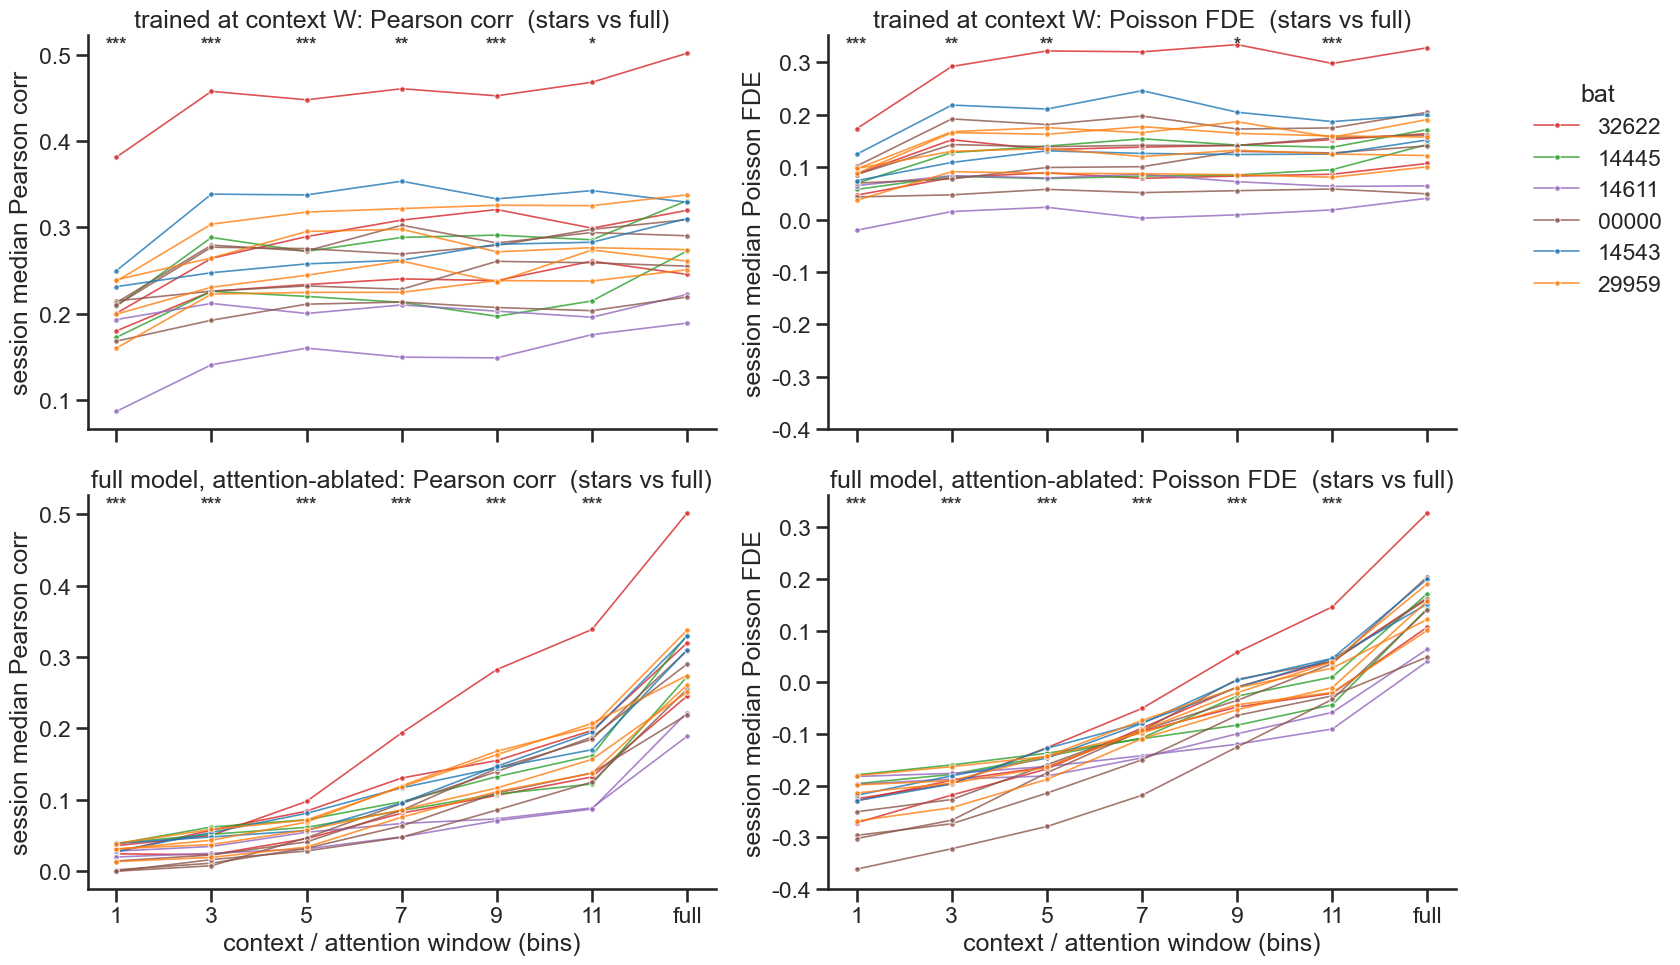

In [18]:
# Per-session medians: one line per session (no shading), coloured by bat.
# Top row  = models trained at each context length.
# Bottom row = the full model with attention ablated to each window (Part 2).
# Stars = paired Wilcoxon (across sessions) of each window vs FULL context.
ctx_sess = (ctx_df.groupby(['session', 'bat', 'context_x'])[['corr', 'fde']]
            .median().reset_index().rename(columns={'context_x': 'x'}))
rf_sess = (rf_df.groupby(['session', 'bat', 'window_x'])[['corr', 'fde']]
           .median().reset_index().rename(columns={'window_x': 'x'}))

bat_pal = bat_palette()
rows_spec = [('trained at context W', ctx_sess),
             ('full model, attention-ablated', rf_sess)]

fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharex=True)
for i, (row_title, df_) in enumerate(rows_spec):
    for j, (metric, label) in enumerate([('corr', 'Pearson corr'),
                                         ('fde', 'Poisson FDE')]):
        ax = axes[i, j]
        sns.lineplot(data=df_, x='x', y=metric, units='session', estimator=None,
                     hue='bat', palette=bat_pal, lw=1.2, alpha=0.8,
                     marker='o', markersize=4, ax=ax,
                     legend=(i == 0 and j == 1))
        ax.set_xticks(CTX_WINDOWS + [ALL_X])
        ax.set_xticklabels([str(w) for w in CTX_WINDOWS] + ['full'])
        ax.set_xlabel('context / attention window (bins)'
                      if i == len(rows_spec) - 1 else '')
        ax.set_ylabel(f'session median {label}')
        if metric == 'fde':            # FDE unbounded below; clip the AXIS only
            ax.set_ylim(-.4, ax.get_ylim()[1])

        # paired Wilcoxon of each window vs FULL context, across sessions;
        # 3-tier stars (n.s. hidden) placed above each window position.
        piv = df_.pivot_table(index='session', columns='x', values=metric)
        ymax = ax.get_ylim()[1]
        if ALL_X in piv:
            for W in CTX_WINDOWS:
                if W not in piv:
                    continue
                _, p = wilcoxon_safe(piv[W] - piv[ALL_X])
                s = stars_for_p(p)
                if s:
                    ax.text(W, ymax, s, ha='center', va='top', fontsize=13,
                            fontweight='bold', color='0.2')
        ax.set_title(f'{row_title}: {label}  (stars vs full)')
# one shared bat legend outside; drop the per-axis one
if axes[0, 1].get_legend() is not None:
    h, l = axes[0, 1].get_legend_handles_labels()
    axes[0, 1].get_legend().remove()
    fig.legend(h, l, title='bat', bbox_to_anchor=(1.02, 0.92), loc='upper left')
sns.despine(fig)
plt.tight_layout()
plt.show()


### Notes / knobs

- **Every-bin evaluation:** Parts 1–2 predict at *every* bin of *every* flight
  (the diagonal of a per-center batch) and pool across flights before scoring --
  not a single time point per flight.
- **No BigBird:** Part 2 restricts the receptive field with the model's own
  padding mask, so bin `c` attends only to `[c-r, c+r]` exactly as it treats
  padding in training -- an *exact* ±(W-1)/2-bin receptive field with no
  cross-layer compounding and no out-of-distribution attention pattern. (BigBird,
  `is_bigbird=True, num_global=0, num_random=0`, is available as an optional
  cross-check but imposes a sliding pattern the baseline wasn't trained with.)
- **Part 3 = train-time, Part 2 = inference-time** versions of the same
  context-length question. Part 3 tiles flights into `window_size=W` segments
  (`stride=W`, non-overlapping); set `stride_train < W` for overlapping training
  segments, or lower `CTX_N_EPOCHS` / `CTX_PATIENCE` for a quick pass. Checkpoints
  cache under `out/bat_former_ctxlen/`. `W=full` is encode-opt
  (`window_size=None` = one segment per flight, padded to the session max).
- **Swap to the joint encoder:** set `MODEL_CHOICE = 'joint'` and implement that
  branch in `load_encoder()`; it only needs the standard
  `model(session, X, mask)` call.
- **Cost:** Part 1/2 splice batches are tiny (flights ~21 bins); lower
  `MAX_FOCAL_PER_SESSION` / `K_DONORS` to speed them up. Part 3 training is the
  expensive step.
